# 00 · Auditoría de datos y definiciones de la investigación

**Proyecto:** Análisis experimental MC4–Skinpass · Ternium Pesquería · producción 2025
**Fase:** 0 (antes de cualquier análisis)

## A. Contexto de la etapa

**¿Qué investigamos?** Una vez controlado por producto, campaña y estructura de la orden, ¿en qué medida la variabilidad geométrica y térmica heredada del Molino Caliente 4 (MC4), frente a las condiciones de operación y de rodillos del propio Skinpass (SKP), explica

- **(A)** el esfuerzo mecánico del Skinpass y su desviación frente al preset (fuerza, bending y tensiones), y
- **(B)** las retenciones por defecto físico, separadas de las retenciones administrativas por peso y programación?

**¿Por qué este notebook va primero?** Porque la propuesta de validación metodológica cita cifras, nombres de columna y definiciones que **todavía no se han verificado contra los archivos**. Si una de ellas está mal (una llave que multiplica filas, un resultado que en realidad es una regla automática, un "Programa" que significa dos cosas), todo lo que se construya encima hereda el error. Es más barato encontrarlo aquí que después de entrenar modelos.

**¿Qué pregunta de la tesis atiende?** Ninguna directamente. Atiende la condición previa de todas: *¿podemos medir lo que decimos que vamos a medir?*

**Trabajo previo que no repetimos** (está en `notebooks/antecedentes/`):

| Notebook | Lo que ya quedó establecido |
|---|---|
| `01_datos` | Cobertura mensual completa, columnas vacías y constantes, corona imposible, `SpyOn` son códigos, el SKP copia espesor/ancho/peso de entrada del MC4, ~5 días entre líneas |
| `02_calidad` | En el MC4 la mayoría de los defectos son reglas automáticas; la etiqueta ESPESOR no se reconstruye con el promedio |
| `03_receta` | El PRAM fija la consigna de enrollado; la temperatura real sigue la consigna de cerca |
| `04_programa` | `Cambio Rodillo Trabajo` no es confiable; el Programa MC4 explica ~45% de la corona |
| `investigacion` | Las retenciones del SKP se reparten entre origen MC4 y origen SKP |

## B. Fundamento conceptual

**1. Unidad de análisis y cardinalidad de la llave.** Cada fila del MC4 es un *rollo*; cada fila del Skinpass es una *pieza*. Si un rollo se corta en dos piezas, las dos heredan exactamente la misma corona, la misma temperatura y el mismo programa del MC4. Para un modelo eso parecen dos observaciones independientes, pero no lo son: la información del MC4 está **duplicada** y el modelo se vuelve demasiado confiado (errores estándar pequeños, validación optimista). Por eso hay que saber cuántas piezas da cada rollo y agrupar por rollo al validar.

**2. Agrupaciones (clusters).** Los rollos de un mismo programa de laminación comparten rodillos, horno y campaña; las piezas de una misma campaña de rodillo del Skinpass comparten el desgaste del rodillo. Estas agrupaciones son las que después usarán los modelos mixtos (efectos aleatorios) y la validación cruzada agrupada. Hay que identificar **qué columna representa qué agrupación**.

**3. Preset contra real.** Antes de procesar cada pieza, el control de *setup* del Skinpass fija un preset de fuerza, bending y tensiones. Durante el proceso, el control dinámico ajusta la fuerza para alcanzar la elongación objetivo. La diferencia Δ = Real − Preset es **lo que el setup no anticipó** para esa pieza. Para que Δ tenga sentido, el preset tiene que existir y ser comparable con el real.

**4. Etiquetas tautológicas.** Si un defecto lo genera una regla automática que compara una medición contra su tolerancia (p. ej., "peso fuera de la orden"), entonces predecir ese defecto con esa misma medición no descubre nada: el modelo solo reaprende la regla. Antes de definir el resultado B hay que separar los defectos de **regla automática** de los que observa un **inspector**.

**5. Pre-tratamiento.** Una variable de control debe estar fijada **antes** de lo que queremos explicar. Si `Dividido` se decidiera como consecuencia de un problema en el Skinpass, controlar por ella bloquearía parte del efecto. Hay que averiguar cuándo se decide.

## C. Objetivo y metodología

| # | Verificación | Por qué | Resultado esperado |
|---|---|---|---|
| 1 | Cifras de la propuesta contra los archivos | Lo que se reporte debe ser reproducible | Tabla *propuesta vs. real* |
| 2 | Nombres de columna de la propuesta → nombres reales | Regla: no inventar nombres | Diccionario de variables con bloque, cobertura y rol |
| 3 | Llave MC4 → SKP y unidad de análisis | No multiplicar ni duplicar observaciones | Cardinalidad rollo → piezas; decisión de unidad |
| 4 | ¿Cuándo se decide `Dividido`? | Saber si es un control válido | Evidencia de pre-tratamiento |
| 5 | Programa MC4, Programa SKP, Colada, campañas de rodillo | Elegir las agrupaciones | Mapa de agrupaciones |
| 6 | Población del resultado A (presets en 0) | Que Δ tenga sentido | Población A definida |
| 7 | Etiquetas del resultado B | Separar físico de administrativo y regla de inspector | Conteo de eventos por definición |

**Técnicas:** solo conteos, tablas cruzadas y gráficas descriptivas. No hay modelos en este notebook.

**Salidas:**
- `resultados/00_diccionario_variables.csv`: diccionario de variables de la propuesta.
- `resultados/00_cifras_propuesta.csv`: cifras de la propuesta contra el dato real.
- `figuras/00_*.png`: figuras de este notebook.

## D. Implementación
### 0. Configuración

In [2]:
# Solo en Colab: descarga el repo (datos incluidos) e instala dependencias. En local no hace nada.
import os, sys, subprocess
if 'google.colab' in sys.modules:
    REPO = '/content/Entregable_Reto'
    if os.path.exists(REPO):
        # La copia de Colab es desechable: se iguala a GitHub aunque tenga figuras o archivos regenerados.
        subprocess.run(['git', '-C', REPO, 'fetch', '-q', 'origin', 'main'], check=True)
        subprocess.run(['git', '-C', REPO, 'reset', '-q', '--hard', 'origin/main'], check=True)
    else:
        subprocess.run(['git', 'clone', '-q', 'https://github.com/DiegoLarrieta/Entregable_Reto.git', REPO], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', f'{REPO}/requirements.txt'], check=True)
    os.chdir(f'{REPO}/notebooks')

In [3]:
# Busca la raíz del repo para importar src/ternium.py (funciona desde notebooks/ y sus subcarpetas).
import sys, re
from pathlib import Path
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'ternium.py').exists())
sys.path.append(str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.ternium import *

estilo()
pd.set_option('display.max_columns', 30, 'display.width', 160)
RESULTADOS = RAIZ / 'resultados'
RESULTADOS.mkdir(exist_ok=True)

In [4]:
# Datos originales: se leen de los Excel (o de su copia en caché Parquet). Nunca se modifican.
mc4 = cargar_mc4()
skp = cargar_skp()
print(f'MC4: {len(mc4):,} rollos · {mc4.shape[1] - 1} columnas')
print(f'SKP: {len(skp):,} piezas · {skp.shape[1] - 1} columnas')

MC4: 149,734 rollos · 280 columnas
SKP: 58,786 piezas · 208 columnas


### 1. Cifras de la propuesta contra los archivos
Recalculamos cada número que cita la propuesta. Para la completitud distinguimos **"tiene dato"** (no está vacío) de **"tiene dato útil"** (no está vacío y no es 0), porque en el preset un 0 puede no ser una medición.

In [5]:
PF, RF = 'Preset Fuerza [kN]', 'Fuerza Real Prom.  [kN]'   # ojo: doble espacio en el nombre real
PB, RB = 'Preset Bending', 'Bending Prom. Real [kN]'

ret = skp['Dictamen'] == 'RETENIDO'
D = defectos_largo(skp)                       # un renglón por defecto registrado en el Skinpass
D['linea'] = D['linea'].fillna('sin dato')
Dret = D[D['ret']]                            # defectos que retienen la pieza (Calidad (k) = RETENIDO)

def piezas_con(mascara_defectos):
    return skp.index.isin(Dret.loc[mascara_defectos, 'row'])

peso_mc4 = piezas_con(Dret['d'].str.startswith('PESO') & (Dret['linea'] == 'MC4_PSQ'))
ancho_mc4 = piezas_con(Dret['d'].str.startswith('ANCHO') & (Dret['linea'] == 'MC4_PSQ'))
t = lambda m: skp.loc[m, 'Peso'].sum() / 1000      # Peso viene en kg

cifras = pd.DataFrame([
    ('Rollos MC4', 149_734, len(mc4)),
    ('Variables MC4', 280, mc4.shape[1] - 1),
    ('Piezas SKP', 58_786, len(skp)),
    ('Variables SKP', 208, skp.shape[1] - 1),
    ('Piezas SKP con al menos un defecto', 12_823, skp['Defecto (1)'].notna().sum()),
    ('Piezas retenidas SKP', 4_415, ret.sum()),
    ('Toneladas retenidas SKP', 82_510, round(t(ret))),
    ('Piezas retenidas por PESO, origen MC4', 1_846, peso_mc4.sum()),
    ('Toneladas retenidas por PESO, origen MC4', 34_235, round(t(peso_mc4))),
    ('Toneladas retenidas por ANCHO, origen MC4', 8_152, round(t(ancho_mc4))),
    ('Fuerza real y preset con dato', 58_719, skp[[PF, RF]].notna().all(axis=1).sum()),
    ('Preset de fuerza con dato útil (≠ 0)', None, (skp[PF].fillna(0) != 0).sum()),
    ('Preset de bending con dato útil (≠ 0)', None, (skp[PB].fillna(0) != 0).sum()),
    ('Elongación con dato', 53_550, skp['Elongación'].notna().sum()),
], columns=['cifra', 'propuesta', 'real'])
cifras['coincide'] = np.where(cifras.propuesta.isna(), '—', np.where(cifras.propuesta == cifras.real, 'sí', 'NO'))
cifras.to_csv(RESULTADOS / '00_cifras_propuesta.csv', index=False)
cifras

,cifra,propuesta,real,coincide
0,Rollos MC4,149734.0,149734,sí
1,Variables MC4,280.0,280,sí
2,Piezas SKP,58786.0,58786,sí
3,Variables SKP,208.0,208,sí
4,Piezas SKP con al menos un defecto,12823.0,12823,sí
5,Piezas retenidas SKP,4415.0,4415,sí
6,Toneladas retenidas SKP,82510.0,82510,sí
7,"Piezas retenidas por PESO, origen MC4",1846.0,1846,sí
8,"Toneladas retenidas por PESO, origen MC4",34235.0,34235,sí
9,"Toneladas retenidas por ANCHO, origen MC4",8152.0,8152,sí


**Qué observamos.** Las cifras de la propuesta se reproducen con los archivos. La única que hay que matizar es la **completitud del preset (99.89%)**: es cierta si se cuenta "tiene dato", pero miles de piezas tienen el preset exactamente en 0. La sección 6 averigua qué significa ese 0.

**Cómo interpretarlo.** La propuesta está bien construida en lo cuantitativo. Lo que falta revisar son las **definiciones**, no los números.

### 2. Diccionario: nombres de la propuesta → columnas reales
Cada variable que menciona la propuesta se busca **por su nombre exacto** en los archivos. Se anota el bloque de la tesis al que pertenece, su cobertura y su rol: respuesta, predictor, control, agrupación, llave, prohibida (fuga de información) o excluida (sin datos).

In [7]:
# (nombre en la propuesta, tabla, columna real, bloque, rol)
V = [
    # Llave y tiempo
    ('Material Salida MC4', 'MC4', 'Material Salida', 'Llave y tiempo', 'llave'),
    ('Material Entrada SKP', 'SKP', 'Material Entrada', 'Llave y tiempo', 'llave'),
    ('Fecha Inicio / Fin MC4', 'MC4', 'Fecha Fin', 'Llave y tiempo', 'derivar'),
    ('Fecha Inicio / Fin SKP', 'SKP', 'Fecha Inicio', 'Llave y tiempo', 'derivar'),
    # Respuesta A: esfuerzo mecánico
    ('Fuerza Real Prom. [kN]', 'SKP', 'Fuerza Real Prom.  [kN]', 'Respuesta A · esfuerzo SKP', 'respuesta'),
    ('Preset Fuerza [kN]', 'SKP', 'Preset Fuerza [kN]', 'Respuesta A · esfuerzo SKP', 'respuesta'),
    ('Bending Prom. Real [kN]', 'SKP', 'Bending Prom. Real [kN]', 'Respuesta A · esfuerzo SKP', 'respuesta'),
    ('Preset Bending', 'SKP', 'Preset Bending', 'Respuesta A · esfuerzo SKP', 'respuesta'),
    ('Back Tensión Real Prom. [kN]', 'SKP', 'Back Tensión Real Prom. [kN]', 'Respuesta A · esfuerzo SKP', 'respuesta'),
    ('Front Tensión Real Prom. [kN]', 'SKP', 'Front Tensión Real Prom. [kN]', 'Respuesta A · esfuerzo SKP', 'respuesta'),
    ('Back Preset Tensión [kN]', 'SKP', 'Back Preset Tensión [kN]', 'Respuesta A · esfuerzo SKP', 'respuesta'),
    ('Front Preset Tensión [kN]', 'SKP', 'Front Preset Tensión [kN]', 'Respuesta A · esfuerzo SKP', 'respuesta'),
    ('Elongación', 'SKP', 'Elongación', 'Respuesta A · esfuerzo SKP', 'respuesta / mediador'),
    # Respuesta B: calidad
    ('Dictamen', 'SKP', 'Dictamen', 'Respuesta B · calidad SKP', 'respuesta'),
    ('Resolución', 'SKP', 'Resolución', 'Respuesta B · calidad SKP', 'definir etiqueta (prohibida como predictor)'),
    ('Defecto (1)', 'SKP', 'Defecto (1)', 'Respuesta B · calidad SKP', 'definir etiqueta'),
    ('Linea Origen (1)', 'SKP', 'Linea Origen (1)', 'Respuesta B · calidad SKP', 'estratificar etiqueta'),
    ('Causa (1)', 'SKP', 'Causa (1)', 'Respuesta B · calidad SKP', 'prohibida'),
    ('Codigo defecto (1)', 'SKP', 'Codigo defecto (1)', 'Respuesta B · calidad SKP', 'definir etiqueta'),
    # Herencia geométrica MC4
    ('Corona Salida', 'MC4', 'Corona Salida', 'MC4 · geometría', 'predictor'),
    ('Acuñamiento Salida', 'MC4', 'Acuñamiento Salida', 'MC4 · geometría', 'predictor'),
    ('Spring Back Salida', 'MC4', 'Spring Back Salida', 'MC4 · geometría', 'predictor'),
    ('Ancho', 'MC4', 'Ancho', 'MC4 · geometría', 'predictor'),
    ('Ancho Objetivo', 'MC4', 'Ancho Objetivo', 'MC4 · geometría', 'derivar (error)'),
    ('Ancho Mínimo', 'MC4', 'Ancho Mínimo', 'MC4 · geometría', 'derivar (tolerancia)'),
    ('Ancho Máximo', 'MC4', 'Ancho Máximo', 'MC4 · geometría', 'derivar (tolerancia)'),
    ('Espesor Final', 'MC4', 'Espesor Final', 'MC4 · geometría', 'predictor'),
    ('Espesor Objetivo', 'MC4', 'Espesor Objetivo', 'MC4 · geometría', 'derivar (error)'),
    ('Taper Medido', 'MC4', 'Taper Medido', 'MC4 · geometría', 'predictor'),
    ('Taper Teórico', 'MC4', 'Taper Teórico', 'MC4 · geometría', 'derivar (ΔTaper)'),
    ('Canteo R1', 'MC4', 'Canteo R1', 'MC4 · geometría', 'predictor (palanca)'),
    ('Canteo R2', 'MC4', 'Canteo R2', 'MC4 · geometría', 'predictor (palanca)'),
    ('Canteo SSP', 'MC4', 'Canteo SSP', 'MC4 · geometría', 'predictor'),
    ('Offset de Ancho Manual', 'MC4', 'Offset de Ancho Manual ', 'MC4 · geometría', 'predictor (palanca)'),
    # Herencia térmica MC4
    ('Temp Acabado Real', 'MC4', 'Temp Acabado Real', 'MC4 · térmica', 'predictor'),
    ('Temp Acabado Obj', 'MC4', 'Temp Acabado Obj', 'MC4 · térmica', 'derivar (ΔT)'),
    ('Temp Enrollado Real', 'MC4', 'Temp Enrollado Real', 'MC4 · térmica', 'predictor'),
    ('Temp Enrollado Obj', 'MC4', 'Temp Enrollado Obj', 'MC4 · térmica', 'derivar (ΔT)'),
    ('Temp. F1', 'MC4', 'Temp. F1', 'MC4 · térmica', 'derivar (caída F1→F7)'),
    ('Temp. F7', 'MC4', 'Temp. F7', 'MC4 · térmica', 'derivar (caída F1→F7)'),
    ('Tempe. F5', 'MC4', 'Tempe. F5', 'MC4 · térmica', 'predictor'),
    ('Temp. Acabador Sup. A', 'MC4', 'Temp. Acabador Sup. A', 'MC4 · térmica', 'derivar (asimetría)'),
    ('Temp. Acabador Sup. B', 'MC4', 'Temp. Acabador Sup. B', 'MC4 · térmica', 'derivar (asimetría)'),
    ('Temperatura Descarga Salida', 'MC4', 'Temperatura Descarga Salida', 'MC4 · térmica', 'predictor'),
    ('Tiempo Estancia', 'MC4', 'Tiempo Estancia', 'MC4 · térmica', 'predictor'),
    ('Tiempo Entre Salida R2 y Entrada F1', 'MC4', 'Tiempo Entre Salida R2 y Entrada F1', 'MC4 · térmica', 'predictor'),
    ('% Uso Cubierta Térmica', 'MC4', '% Uso Cubierta Térmica', 'MC4 · térmica', 'predictor'),
    ('topSpyOn/botSpyOn H/M/T', 'MC4', 'topSpyOnH', 'MC4 · térmica', 'código (no numérico)'),
    ('Tensión de Looper 1-6', 'MC4', 'Tensión de Looper 1 [Mpa]', 'MC4 · térmica', 'derivar (media/máx)'),
    ('Uso Aceite Rolado', 'MC4', 'Uso Aceite Rolado', 'MC4 · térmica', 'predictor'),
    ('Horno', 'MC4', 'Horno', 'MC4 · térmica', 'predictor'),
    ('Enrollador', 'MC4', 'Enrollador', 'MC4 · térmica', 'predictor'),
    ('Cambio Rodillo Trabajo', 'MC4', 'Cambio Rodillo Trabajo', 'MC4 · térmica', 'excluida (no confiable)'),
    # Rodillos y operación SKP
    ('Rodillo de Trabajo', 'SKP', 'Rodillo de Trabajo', 'SKP · rodillos y operación', 'agrupación / derivar desgaste'),
    ('Rodillo de Trabajo Pareja', 'SKP', 'Rodillo de Trabajo Pareja', 'SKP · rodillos y operación', 'agrupación'),
    ('Rodillo de Trabajo Corona Entrada', 'SKP', 'Rodillo de Trabajo Corona Entrada', 'SKP · rodillos y operación', 'predictor'),
    ('Pareja Corona', 'SKP', 'Rodillo de Trabajo Pareja Corona', 'SKP · rodillos y operación', 'predictor'),
    ('Rodillo de Trabajo Diám. Entrada', 'SKP', 'Rodillo de Trabajo Diám. Entrada', 'SKP · rodillos y operación', 'predictor'),
    ('Pareja Diám.', 'SKP', 'Rodillo de Trabajo Pareja Diám. entrada', 'SKP · rodillos y operación', 'predictor'),
    ('Rodillo Apoyo Superior Diám.', 'SKP', 'Rodillo Apoyo Superior Diám.', 'SKP · rodillos y operación', 'predictor'),
    ('Rodillo Apoyo Inferior Diám.', 'SKP', 'Rodillo Apoyo Inferior Diám.', 'SKP · rodillos y operación', 'predictor'),
    ('Modo / Modo Molino', 'SKP', 'Modo Molino', 'SKP · rodillos y operación', 'filtro de población'),
    ('Medidor de Espesor', 'SKP', 'Medidor de Espesor', 'SKP · rodillos y operación', 'predictor'),
    ('Riesgo de Spring Back', 'SKP', 'Riesgo de Spring Back', 'SKP · rodillos y operación', 'predictor'),
    ('Usuario', 'SKP', 'Usuario', 'SKP · rodillos y operación', 'predictor'),
    # Controles
    ('Grado Salida', 'SKP', 'Grado Salida', 'Controles', 'control'),
    ('Grado', 'SKP', 'Grado', 'Controles', 'alternativa a Grado Salida'),
    ('Grado Planchón', 'MC4', 'Grado Planchón', 'Controles', 'control'),
    ('Norma', 'SKP', 'Norma', 'Controles', 'control'),
    ('PRAM', 'SKP', 'PRAM', 'Controles', 'control'),
    ('Programa (SKP)', 'SKP', 'Programa', 'Controles', 'agrupación'),
    ('Programa (MC4)', 'MC4', 'Programa', 'Controles', 'agrupación'),
    ('Dividido', 'SKP', 'Dividido', 'Controles', 'control'),
    ('Es Reproceso', 'SKP', 'Es Reproceso', 'Controles', 'control'),
    ('Espesor Entrada', 'SKP', 'Espesor Entrada', 'Controles', 'control'),
    ('Ancho Entrada', 'SKP', 'Ancho Entrada', 'Controles', 'control'),
    ('Peso Entrada', 'SKP', 'Peso Entrada', 'Controles', 'control'),
    ('Peso Mínimo', 'SKP', 'Peso Mínimo', 'Controles', 'derivar (holgura)'),
    ('Peso Máximo', 'SKP', 'Peso Máximo', 'Controles', 'derivar (holgura)'),
    ('Colada', 'MC4', 'Colada', 'Controles', 'agrupación'),
    ('Secuencia', 'MC4', 'Secuencia', 'Controles', 'control'),
    ('Peso Báscula (intervención A)', 'MC4', 'Peso Báscula', 'Controles', 'excluida (0 en la mayoría)'),
    ('Peso (MC4)', 'MC4', 'Peso', 'Controles', 'usar en lugar de Peso Báscula'),
    # Fuga de información y sin datos
    ('Calidad Sugerida', 'SKP', 'Calidad Sugerida', 'Fuga de información', 'prohibida'),
    ('Observaciones Calidad', 'SKP', 'Observaciones Calidad', 'Fuga de información', 'prohibida'),
    ('Muestreado', 'SKP', 'Muestreado', 'Fuga de información', 'prohibida'),
    ('Empaque Cumple', 'SKP', 'Empaque Cumple', 'Fuga de información', 'prohibida'),
    ('Siguiente Accion/Proceso', 'MC4', 'Proceso Siguiente', 'Fuga de información', 'prohibida'),
    ('Forma Final', 'SKP', 'Forma Final', 'Sin datos', 'excluida'),
    ('Código Forma', 'SKP', 'Código Forma', 'Sin datos', 'excluida'),
    ('Reflectividad', 'SKP', 'Reflectividad', 'Sin datos', 'excluida'),
    ('Acabado Superficial', 'SKP', 'Acabado Superficial', 'Sin datos', 'excluida'),
    ('Temp. Acabador Inf.', 'MC4', 'Temp. Acabador Inf.', 'Sin datos', 'excluida'),
    ('Ancho Cuerpo', 'SKP', 'Ancho Cuerpo', 'Sin datos', 'excluida'),
    ('Subnorma', 'SKP', 'Subnorma', 'Sin datos', 'excluida'),
]
tablas = {'MC4': mc4, 'SKP': skp}
filas = []
for nombre, tabla, col, bloque, rol in V:
    df = tablas[tabla]
    existe = col in df.columns
    s = df[col] if existe else None
    filas.append({
        'nombre_propuesta': nombre, 'tabla': tabla, 'columna_real': col, 'existe': existe,
        'nombre_distinto': existe and col != nombre.split(' (')[0],
        'bloque': bloque, 'rol': rol,
        'cobertura_%': round(100 * s.notna().mean(), 2) if existe else np.nan,
        'distintos': s.nunique() if existe else np.nan,
        'tipo': str(s.dtype) if existe else '',
    })
dicc = pd.DataFrame(filas)
dicc.to_csv(RESULTADOS / '00_diccionario_variables.csv', index=False)
print(f'{len(dicc)} variables de la propuesta · existen todas: {dicc.existe.all()}')
print('No existe:', dicc.loc[~dicc.existe, 'nombre_propuesta'].tolist())
dicc[['nombre_propuesta', 'columna_real', 'bloque', 'rol', 'cobertura_%', 'distintos']]

95 variables de la propuesta · existen todas: True
No existe: []


,nombre_propuesta,columna_real,bloque,rol,cobertura_%,distintos
0,Material Salida MC4,Material Salida,Llave y tiempo,llave,100.00,149734
1,Material Entrada SKP,Material Entrada,Llave y tiempo,llave,100.00,49557
2,Fecha Inicio / Fin MC4,Fecha Fin,Llave y tiempo,derivar,100.00,149734
3,Fecha Inicio / Fin SKP,Fecha Inicio,Llave y tiempo,derivar,100.00,58786
4,Fuerza Real Prom. [kN],Fuerza Real Prom. [kN],Respuesta A · esfuerzo SKP,respuesta,99.89,28499
...,...,...,...,...,...,...
90,Reflectividad,Reflectividad,Sin datos,excluida,0.00,0
91,Acabado Superficial,Acabado Superficial,Sin datos,excluida,0.01,2
92,Temp. Acabador Inf.,Temp. Acabador Inf.,Sin datos,excluida,0.00,3
93,Ancho Cuerpo,Ancho Cuerpo,Sin datos,excluida,10.19,835


In [8]:
# Columnas cuyo nombre real tiene espacios de más (fuente común de KeyError silenciosos).
raros = [(t, c) for t, df in tablas.items() for c in df.columns if c != c.strip() or '  ' in c]
pd.DataFrame(raros, columns=['tabla', 'columna (repr)']).assign(**{'columna (repr)': lambda d: d['columna (repr)'].map(repr)})

,tabla,columna (repr)
0,MC4,'Espesor Barra '
1,MC4,'Offset de Ancho Manual '
2,SKP,'Fuerza Real Prom. [kN]'


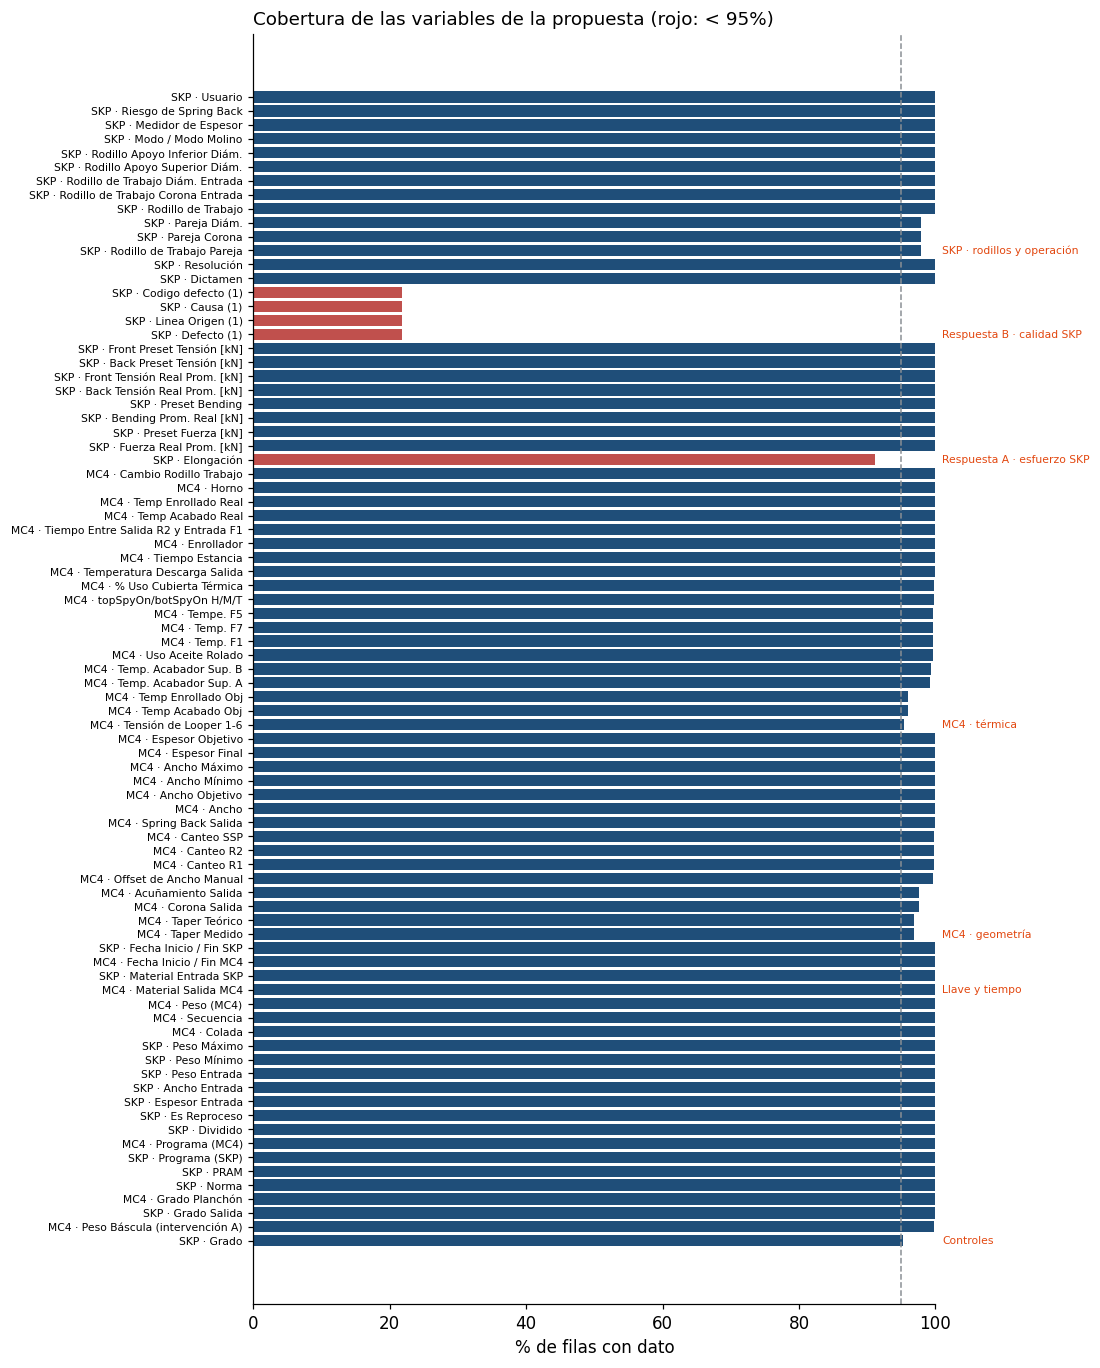

In [9]:
# Figura: cobertura por bloque (solo las variables con dato).
d = dicc[dicc.existe & ~dicc.bloque.isin(['Sin datos', 'Fuga de información'])].copy()
d['etq'] = d.tabla + ' · ' + d.nombre_propuesta
d = d.sort_values(['bloque', 'cobertura_%'])
fig, ax = plt.subplots(figsize=(8, 15))
col = d['cobertura_%'].map(lambda v: COLORES['rojo'] if v < 95 else COLORES['azul'])
ax.barh(d.etq, d['cobertura_%'], color=col)
ax.axvline(95, color=COLORES['gris'], ls='--', lw=1)
ax.set_xlim(0, 100); ax.set_xlabel('% de filas con dato'); ax.tick_params(axis='y', labelsize=7)
prev = None
for i, b in enumerate(d.bloque):
    if b != prev:
        ax.text(101, i, b, fontsize=7, color=COLORES['naranja'], va='center'); prev = b
ax.set_title('Cobertura de las variables de la propuesta (rojo: < 95%)')
guardar(fig, '00_cobertura_variables'); plt.show()

**Qué observamos.**
- **Todas las variables que nombra la propuesta existen**, pero dos tienen espacios de más en el nombre real (`'Fuerza Real Prom.  [kN]'` y `'Offset de Ancho Manual '`). Hay que usar el nombre exacto.
- `Siguiente Accion/Proceso` se llama `Proceso Siguiente` y solo existe en el MC4.
- **`Peso Báscula` no sirve para la intervención A.** La propuesta la menciona como el peso a validar, pero vale 0 en la mayoría de los rollos (`antecedentes/01_datos`). El peso confiable es `Peso`.
- Casi todo el bloque mecánico y de rodillos tiene cobertura cercana al 100%. Las de menor cobertura son `Elongación` (91%, por el modo Fuerza), las tensiones de looper y `Grado` (por eso la propuesta prefiere `Grado Salida`).

**Qué no podemos afirmar todavía.** Que una variable tenga cobertura alta no dice que tenga **variación útil**. Eso se revisa en el EDA (Notebook 01).

### 3. La llave MC4 → Skinpass y la unidad de análisis
`Material Entrada` del Skinpass debe coincidir con `Material Salida` del MC4. Verificamos tres cosas: que la llave sea única del lado del MC4, cuántas piezas da cada rollo y si el join cambia el número de filas.

In [10]:
print('Material Salida duplicado en MC4:', mc4['Material Salida'].duplicated().sum())
print('Material Salida duplicado en SKP (identificador de pieza):', skp['Material Salida'].duplicated().sum())
liga = skp['Material Entrada'].isin(mc4['Material Salida'])
print(f'Piezas SKP que encuentran su rollo MC4: {liga.sum():,} ({liga.mean():.1%})')

piezas_por_rollo = skp.groupby('Material Entrada').size()
print(f'\nRollos distintos que entran al SKP: {len(piezas_por_rollo):,}  →  piezas: {len(skp):,}')
print(piezas_por_rollo.value_counts().sort_index().rename('rollos').to_frame().T.to_string())

L = unir_mc4_skp(mc4, skp)          # join desde el Skinpass (muchas piezas → un rollo)
print(f'\nFilas tras el join: {len(L):,} (= piezas ligadas: {liga.sum():,}) → el join no multiplica filas.')
print(f"Piezas que repiten la información MC4 de otra pieza: {L['Material Entrada'].duplicated().sum():,}")
dias = (L['Fecha Inicio'] - L['Fecha Fin MC4']).dt.total_seconds() / 86400
print(f'Piezas que entran al SKP antes de que el rollo saliera del MC4: {(dias < 0).sum()}')
print(f'Días MC4 → SKP: mediana {dias.median():.1f} · p90 {dias.quantile(.9):.1f}')

Material Salida duplicado en MC4: 0
Material Salida duplicado en SKP (identificador de pieza): 0
Piezas SKP que encuentran su rollo MC4: 57,099 (97.1%)

Rollos distintos que entran al SKP: 49,557  →  piezas: 58,786
            1     2    3  4
rollos  40770  8352  428  7

Filas tras el join: 57,099 (= piezas ligadas: 57,099) → el join no multiplica filas.
Piezas que repiten la información MC4 de otra pieza: 8,956
Piezas que entran al SKP antes de que el rollo saliera del MC4: 0
Días MC4 → SKP: mediana 5.3 · p90 10.9


**Qué observamos.** La llave es única en el MC4, así que el join desde el Skinpass **no multiplica filas**. Pero unas 9 mil piezas comparten su rollo con otra: repiten exactamente la información del MC4. El orden temporal es consistente (ninguna pieza entra antes de que su rollo salga del MC4).

**Decisión.** Unidad de análisis = **pieza del Skinpass**, porque el esfuerzo y el dictamen se miden por pieza. Al validar y al calcular errores estándar, las piezas de un mismo rollo van siempre **juntas** (nunca una en entrenamiento y otra en prueba).

### 4. ¿Cuándo se decide `Dividido`?
Si la división responde al peso de la orden (planeación), se decide **antes** del Skinpass y es un control válido. Comparamos el peso del rollo que llega (`Peso Entrada`) contra el peso máximo que admite la orden del Skinpass (`Peso Máximo`).

In [11]:
r = skp.groupby('Material Entrada').agg(
    PE=('Peso Entrada', 'first'), PMax=('Peso Máximo', 'first'), div=('Dividido', 'first'),
    piezas=('Peso', 'size'), suma_piezas=('Peso', 'sum'))
r['excede'] = np.where(r.PE > r.PMax, 'Excede el peso máximo', 'Cabe en la orden')
tab = pd.crosstab(r.excede, r['div'])
print(tab.to_string()); print()
print((100 * pd.crosstab(r.excede, r['div'], normalize='index')).round(1).to_string())
print(f"\nSuma del peso de las piezas / peso de entrada (mediana): {(r.suma_piezas / r.PE).median():.3f}")
print(f"Dividido = SI vs. piezas > 1 (concordancia): {((r['div'] == 'SI') == (r.piezas > 1)).mean():.1%}")

div                       NO    SI
excede                            
Cabe en la orden       38919   169
Excede el peso máximo   2110  8359

div                      NO    SI
excede                           
Cabe en la orden       99.6   0.4
Excede el peso máximo  20.2  79.8

Suma del peso de las piezas / peso de entrada (mediana): 0.993
Dividido = SI vs. piezas > 1 (concordancia): 99.2%


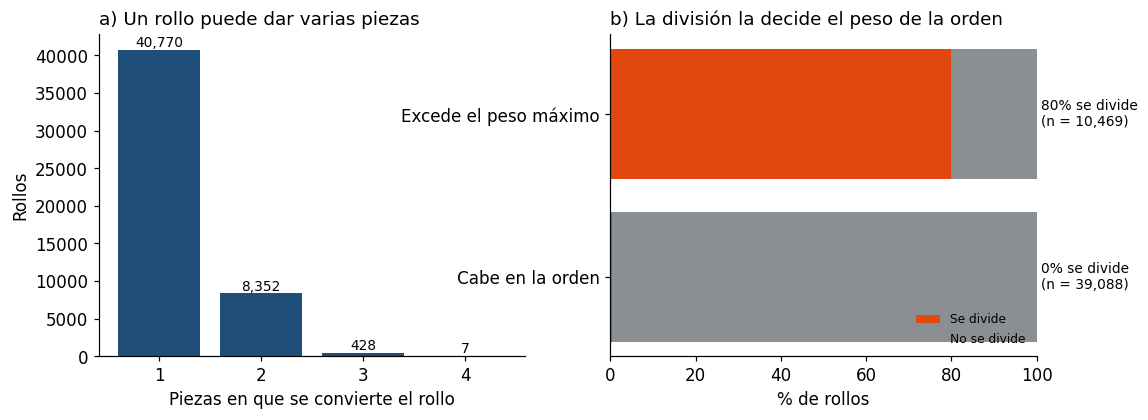

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
pr = piezas_por_rollo.value_counts().sort_index()
ax[0].bar(pr.index.astype(str), pr.values, color=COLORES['azul'])
for x, v in zip(pr.index.astype(str), pr.values):
    ax[0].text(x, v, f'{v:,}', ha='center', va='bottom', fontsize=9)
ax[0].set_xlabel('Piezas en que se convierte el rollo'); ax[0].set_ylabel('Rollos')
ax[0].set_title('a) Un rollo puede dar varias piezas')
p = 100 * pd.crosstab(r.excede, r['div'], normalize='index')
ax[1].barh(p.index, p['SI'], color=COLORES['naranja'], label='Se divide')
ax[1].barh(p.index, p['NO'], left=p['SI'], color=COLORES['gris'], label='No se divide')
for i, (s, n) in enumerate(zip(p['SI'], tab.sum(axis=1))):
    ax[1].text(101, i, f'{s:.0f}% se divide\n(n = {n:,})', va='center', fontsize=9)
ax[1].set_xlim(0, 100); ax[1].set_xlabel('% de rollos'); ax[1].legend(loc='lower right', fontsize=8)
ax[1].set_title('b) La división la decide el peso de la orden')
guardar(fig, '00_llave_dividido'); plt.show()

**Qué observamos.** Cuando el rollo cabe en el peso máximo de la orden, casi nunca se divide (99.6% no). Cuando lo excede, se divide en 4 de cada 5 casos. Además, la suma del peso de las piezas es prácticamente el peso de entrada: el rollo se corta, no se pierde material.

**Cómo interpretarlo.** `Dividido` es una **decisión de planeación** determinada por el peso del rollo frente a la orden; se toma antes de procesar. Es un control válido.

**Hallazgo extra para la intervención A.** Unos 2 mil rollos **excedían** el peso máximo y **no** se dividieron. Son candidatos naturales a retención por PESO(+). Se analizará en el EDA.

### 5. Las agrupaciones: Programa MC4, Programa SKP, Colada y campañas de rodillo
La propuesta usa "Programa" y "Colada" como efectos aleatorios. Hay dos columnas `Programa`, una en cada tabla. ¿Son lo mismo?

In [13]:
s = L.sort_values('Fecha Inicio').copy()
s['Programa SKP'] = s['Programa']
s['Programa MC4'] = s['Programa MC4']
# Campaña de rodillo: racha contigua (en orden temporal) con el mismo rodillo de trabajo.
s['Campaña rodillo'] = (s['Rodillo de Trabajo'] != s['Rodillo de Trabajo'].shift()).cumsum()

print('¿Programa SKP == Programa MC4 en la misma pieza?',
      (s['Programa SKP'].astype(str) == s['Programa MC4'].astype('Int64').astype(str)).mean())

def resumen(col):
    g = s.groupby(col)
    return pd.Series({'grupos': g.ngroups, 'piezas por grupo (mediana)': g.size().median(),
                      'grupos con 1 pieza (%)': round(100 * (g.size() == 1).mean(), 1)})
agr = pd.DataFrame({c: resumen(c) for c in ['Programa MC4', 'Programa SKP', 'Campaña rodillo', 'Colada MC4']}).T
print(agr.to_string())

cruce = pd.Series({
    'Programas MC4 dentro de un Programa SKP (mediana)': s.groupby('Programa SKP')['Programa MC4'].nunique().median(),
    'Programas SKP que recibe un Programa MC4 (mediana)': s.groupby('Programa MC4')['Programa SKP'].nunique().median(),
    'Campañas de rodillo dentro de un Programa SKP (mediana)': s.groupby('Programa SKP')['Campaña rodillo'].nunique().median(),
    'Rachas contiguas de un mismo Programa SKP (mediana)': s.assign(r=(s['Programa SKP'] != s['Programa SKP'].shift()).cumsum()).groupby('Programa SKP').r.nunique().median(),
    'Horas que dura un Programa SKP (mediana)': s.groupby('Programa SKP')['Fecha Inicio'].agg(lambda x: (x.max() - x.min()).total_seconds() / 3600).median(),
    'Rodillos de trabajo distintos': s['Rodillo de Trabajo'].nunique(),
})
print(); print(cruce.round(1).to_string())

¿Programa SKP == Programa MC4 en la misma pieza? 0.0
                  grupos  piezas por grupo (mediana)  grupos con 1 pieza (%)
Programa MC4      1712.0                        30.0                     2.3
Programa SKP       863.0                        73.0                     0.3
Campaña rodillo    668.0                        84.0                     0.1
Colada MC4       11900.0                         3.0                    23.7

Programas MC4 dentro de un Programa SKP (mediana)          12.0
Programas SKP que recibe un Programa MC4 (mediana)          6.0
Campañas de rodillo dentro de un Programa SKP (mediana)     1.0
Rachas contiguas de un mismo Programa SKP (mediana)         1.0
Horas que dura un Programa SKP (mediana)                   10.5
Rodillos de trabajo distintos                              35.0


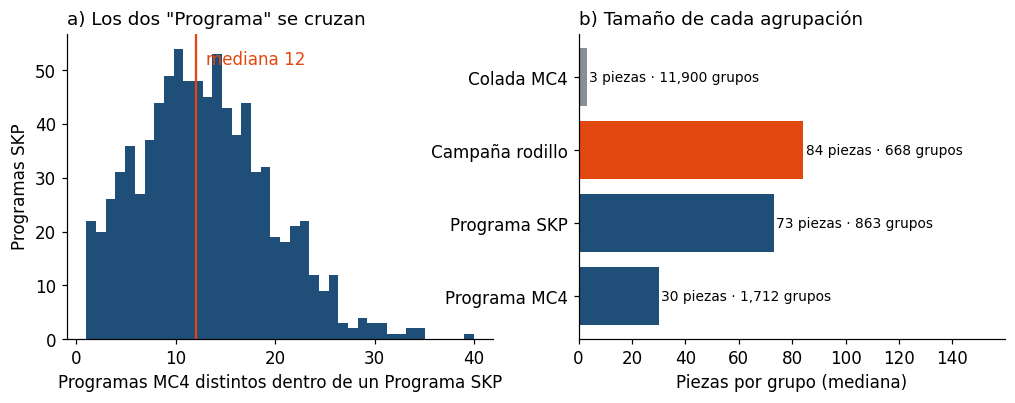

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
a = s.groupby('Programa SKP')['Programa MC4'].nunique()
ax[0].hist(a.clip(upper=40), bins=40, color=COLORES['azul'])
ax[0].axvline(a.median(), color=COLORES['naranja']); ax[0].text(a.median() + 1, ax[0].get_ylim()[1] * .9, f'mediana {a.median():.0f}', color=COLORES['naranja'])
ax[0].set_xlabel('Programas MC4 distintos dentro de un Programa SKP'); ax[0].set_ylabel('Programas SKP')
ax[0].set_title('a) Los dos "Programa" se cruzan')
n = agr['piezas por grupo (mediana)']
ax[1].barh(n.index, n.values, color=[COLORES['azul'], COLORES['azul'], COLORES['naranja'], COLORES['gris']])
for i, (v, g) in enumerate(zip(n.values, agr.grupos)):
    ax[1].text(v + 1, i, f'{v:.0f} piezas · {int(g):,} grupos', va='center', fontsize=9)
ax[1].set_xlabel('Piezas por grupo (mediana)'); ax[1].set_xlim(0, n.max() * 1.9)
ax[1].set_title('b) Tamaño de cada agrupación')
guardar(fig, '00_agrupaciones'); plt.show()

**Qué observamos.**
- `Programa` del MC4 y `Programa` del Skinpass **nunca coinciden**: son dos calendarios distintos.
- Un **Programa SKP** es un bloque continuo de unas 10 horas y ~74 piezas, que cae dentro de **una sola campaña de rodillo** del Skinpass y mezcla rollos de ~12 programas del MC4.
- Un **Programa MC4** se reparte entre varios programas del Skinpass. Las dos agrupaciones están **cruzadas**, no anidadas.
- **Colada** (química del acero) da pocas piezas por grupo (mediana 3) y muchas coladas tienen una sola pieza.

**Decisiones.**
- *Programa MC4* representa la **herencia del molino caliente** (mismos rodillos del MC4, mismo horno, misma campaña).
- *Programa SKP / campaña de rodillo* representa las **condiciones del Skinpass**.
- En los modelos mixtos se usan como efectos aleatorios **cruzados**. Colada se prueba, pero se retirará si no captura varianza.
- La validación agrupará por Programa MC4 (para no filtrar herencia del MC4) y, en otra versión, por campaña de rodillo.

### 6. Población del resultado A: ¿cuándo tiene sentido Δ = Real − Preset?
El Skinpass trabaja en dos modos: **Elongación** (la consigna es el estiramiento y la fuerza resulta) y **Fuerza / RCO** (la consigna es la fuerza). Revisamos dónde aparecen los presets en 0.

In [15]:
print('Preset de FUERZA = 0'); print(pd.crosstab(skp['Modo Molino'], skp[PF] == 0, colnames=['= 0']).to_string())
print('\nPreset de BENDING = 0'); print(pd.crosstab(skp['Modo Molino'], skp[PB] == 0, colnames=['= 0']).to_string())
e = skp[skp['Modo Molino'] == 'Elongación'].copy()
e['pb0'] = np.where(e[PB] == 0, 'Preset = 0', 'Preset ≠ 0')
print('\nBending REAL según el preset (modo Elongación):')
print(e.groupby('pb0')[RB].describe(percentiles=[.1, .5, .9]).round(0).to_string())
print(f"\nValores distintos del preset de bending: {e[PB].nunique()} · más comunes: {e[PB].value_counts().head(7).to_dict()}")
print(f"Bending real negativo: {(e[RB] < 0).mean():.0%}")
print(f"Fuerza real / preset (mediana, modo Elongación): {(e[RF] / e[PF].replace(0, np.nan)).median():.2f}")

Preset de FUERZA = 0
= 0          False  True 
Modo Molino              
Elongación   53225     35
Fuerza        1016   4510

Preset de BENDING = 0
= 0          False  True 
Modo Molino              
Elongación   47437   5823
Fuerza        4410   1116

Bending REAL según el preset (modo Elongación):
              count  mean    std    min    10%   50%    90%    max
pb0                                                               
Preset = 0   5823.0 -38.0  129.0 -431.0 -191.0 -47.0  124.0  689.0
Preset ≠ 0  47404.0  49.0  169.0 -431.0 -164.0  55.0  254.0  686.0

Valores distintos del preset de bending: 265 · más comunes: {100.0: 7802, 0.0: 5823, 50.0: 4228, -100.0: 4211, 200.0: 4166, -50.0: 3263, 150.0: 2508}
Bending real negativo: 41%
Fuerza real / preset (mediana, modo Elongación): 0.82


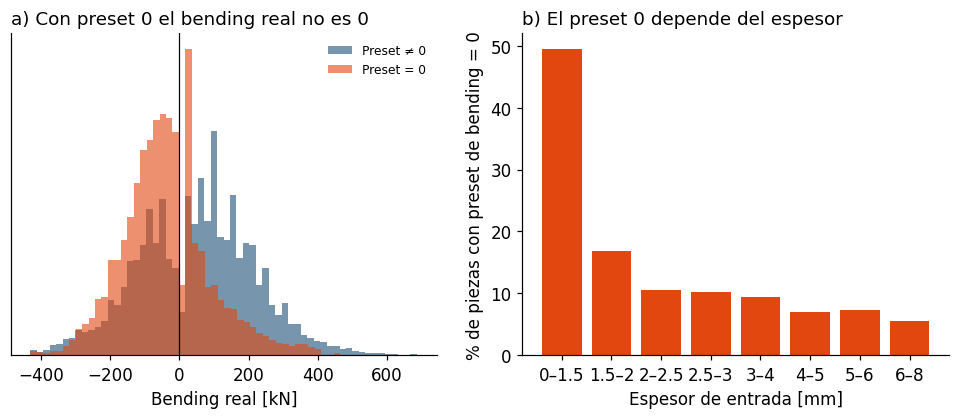

In [16]:
e['Espesor'] = pd.cut(e['Espesor Entrada'], [0, 1.5, 2, 2.5, 3, 4, 5, 6, 8])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for g, c in [('Preset ≠ 0', COLORES['azul']), ('Preset = 0', COLORES['naranja'])]:
    ax[0].hist(e.loc[e.pb0 == g, RB].clip(-450, 700), bins=60, alpha=.6, density=True, color=c, label=g)
ax[0].axvline(0, color='k', lw=.8)
ax[0].set_xlabel('Bending real [kN]'); ax[0].set_yticks([]); ax[0].legend(fontsize=8)
ax[0].set_title('a) Con preset 0 el bending real no es 0')
p0 = 100 * e.groupby('Espesor', observed=True)[PB].apply(lambda x: (x == 0).mean())
ax[1].bar([f'{i.left:g}–{i.right:g}' for i in p0.index], p0.values, color=COLORES['naranja'])
ax[1].set_xlabel('Espesor de entrada [mm]'); ax[1].set_ylabel('% de piezas con preset de bending = 0')
ax[1].set_title('b) El preset 0 depende del espesor')
guardar(fig, '00_preset_bending'); plt.show()

**Qué observamos.**
- El **preset de fuerza en 0** aparece casi solo en modo **Fuerza (RCO)**. En ese modo la consigna es la fuerza misma, así que no hay un "preset" comparable y Δ Fuerza no significa nada.
- El **preset de bending en 0** aparece en miles de piezas en modo **Elongación**, pero se comporta como un **valor válido** y no como un faltante:
  - el bending tiene signo (cerca del 40% de los reales son negativos) y el 0 está rodeado de valores frecuentes como ±50 y ±100;
  - con preset 0 el real **no** es 0;
  - es mucho más frecuente en lámina delgada, lo que es un patrón de proceso y no un error de registro.
- La fuerza real queda en mediana ~18% debajo del preset. Es un sesgo sistemático del setup.

**Decisiones** (anotadas en `docs/plan_de_analisis.md`):
1. **Población A = piezas en modo Elongación.**
2. El preset de bending en 0 se conserva como consigna neutra.
3. No se interpreta el **nivel** promedio de Δ (puede ser un margen intencional), sino su **variación entre piezas dentro de un mismo producto**.
4. Se modelan en paralelo **Δ y el valor Real**, porque no sabemos qué variables usa hoy el modelo de setup.

### 7. Resultado B: ¿qué retenciones son físicas y cuáles administrativas?
Cada defecto registrado en el Skinpass trae su `Linea Origen (k)` (qué línea lo provocó), su calificación `Calidad (k)` y `Registro Automatico (k)` (1 = lo generó una regla del sistema; 0 = lo registró un inspector).

La propuesta llama "administrativas" a las retenciones por peso y programación, pero no da una regla exacta. Hay dos fuentes posibles y las comparamos:
- **Por resolución:** `Resolución` = POR PROGRAMACION.
- **Por defecto:** todos los defectos que retienen la pieza son de PESO.

In [17]:
# Defectos que retienen, por tipo, origen y si son de regla o de inspector.
Dret = Dret.assign(tipo=np.where(Dret.d.str.startswith('PESO'), 'PESO', Dret.d),
                   origen=Dret.linea.map({'SKP_PSQ': 'SKP', 'MC4_PSQ': 'MC4'}).fillna('otra'),
                   regla=np.where(Dret.a == 1, 'regla automática', 'inspector'))
top = (Dret.groupby(['d', 'origen']).agg(piezas=('row', 'nunique'), automatico_pct=('a', 'mean'))
       .sort_values('piezas', ascending=False).head(14))
top['automatico_pct'] = (100 * top.automatico_pct).round(0)
top

,,piezas,automatico_pct
d,origen,,
ESPESOR (+/-),SKP,1051,100.0
PESO (-),MC4,959,100.0
PESO (+),MC4,887,100.0
PESO (-),SKP,444,100.0
ANCHO (-),MC4,272,76.0
PESO (+),SKP,272,100.0
MAL ENROLLADO,SKP,267,0.0
ANCHO (+),MC4,164,97.0
% ELONGACIÓN TEMPLES (+/-),SKP,100,100.0


In [18]:
# Para cada pieza retenida: ¿la retienen solo defectos de PESO? ¿qué origen tienen sus defectos físicos?
P = pd.DataFrame(index=skp.index[ret])
g = Dret.groupby('row')
P['solo_peso'] = g['tipo'].apply(lambda t: (t == 'PESO').all()).reindex(P.index, fill_value=False)
P['res_prog'] = skp.loc[P.index, 'Resolución'].eq('POR PROGRAMACION')

fis = Dret[Dret.tipo != 'PESO']
orig = fis.groupby('row').origen.agg(lambda o: 'Ambas' if {'SKP', 'MC4'} <= set(o) else ('SKP' if 'SKP' in set(o) else ('MC4' if 'MC4' in set(o) else 'otra')))
insp = fis[fis.a == 0].groupby('row').size()

defs = {
    'D1 · por resolución (POR PROGRAMACION)': P.res_prog,
    'D2 · por defecto (solo PESO)': P.solo_peso,
    'D3 · intersección (D1 y D2)': P.res_prog & P.solo_peso,
}
filas = []
for nombre, adm in defs.items():
    fisicas = P.index[~adm]
    o = orig.reindex(fisicas)
    filas.append({
        'definición de administrativa': nombre,
        'administrativas': int(adm.sum()),
        'físicas': len(fisicas),
        'físicas origen SKP': int((o == 'SKP').sum()),
        'físicas origen MC4': int((o == 'MC4').sum()),
        'físicas ambas': int((o == 'Ambas').sum()),
        'físicas sin defecto físico (solo PESO)': int(o.isna().sum()),
        'físicas con defecto de INSPECTOR': int(insp.reindex(fisicas).notna().sum()),
    })
tabla_B = pd.DataFrame(filas).set_index('definición de administrativa').T
print(pd.crosstab(P.res_prog.map({True: 'Resolución = POR PROGRAMACION', False: 'otra resolución'}),
                  P.solo_peso.map({True: 'solo PESO', False: 'algún defecto no-PESO'})).to_string())
tabla_B

solo_peso                      algún defecto no-PESO  solo PESO
res_prog                                                       
Resolución = POR PROGRAMACION                    278       1766
otra resolución                                 2051        320


definición de administrativa,D1 · por resolución (POR PROGRAMACION),D2 · por defecto (solo PESO),D3 · intersección (D1 y D2)
administrativas,2044,2086,1766
físicas,2371,2329,2649
físicas origen SKP,1605,1611,1611
físicas origen MC4,377,648,648
físicas ambas,62,62,62
físicas sin defecto físico (solo PESO),320,0,320
físicas con defecto de INSPECTOR,887,887,887


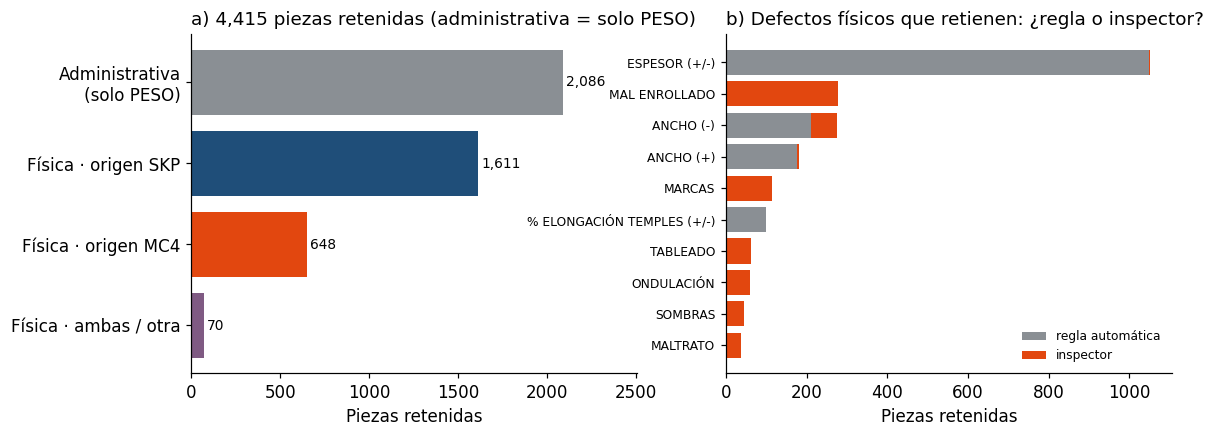

In [20]:
# Figura: piezas retenidas descompuestas (definición D2) y cuántas tienen defecto de inspector.
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4))
o2 = orig.reindex(P.index[~P.solo_peso])
comp = pd.Series({'Administrativa\n(solo PESO)': P.solo_peso.sum(), 'Física · origen SKP': (o2 == 'SKP').sum(),
                  'Física · origen MC4': (o2 == 'MC4').sum(), 'Física · ambas / otra': o2.isin(['Ambas', 'otra']).sum()})
cols = [COLORES['gris'], COLORES['azul'], COLORES['naranja'], '#7f5a83']
ax[0].barh(comp.index[::-1], comp.values[::-1], color=cols[::-1])
for i, v in enumerate(comp.values[::-1]):
    ax[0].text(v + 20, i, f'{v:,}', va='center', fontsize=9)
ax[0].set_xlabel('Piezas retenidas'); ax[0].set_xlim(0, comp.max() * 1.2)
ax[0].set_title(f'a) {ret.sum():,} piezas retenidas (administrativa = solo PESO)')
tt = (fis.groupby(['d', 'regla']).row.nunique().unstack(fill_value=0))
tt = tt.loc[tt.sum(axis=1).sort_values(ascending=False).index[:10]][::-1]
ax[1].barh(tt.index, tt.get('regla automática', 0), color=COLORES['gris'], label='regla automática')
ax[1].barh(tt.index, tt.get('inspector', 0), left=tt.get('regla automática', 0), color=COLORES['naranja'], label='inspector')
ax[1].set_xlabel('Piezas retenidas'); ax[1].legend(fontsize=8, loc='lower right'); ax[1].tick_params(axis='y', labelsize=8)
ax[1].set_title('b) Defectos físicos que retienen: ¿regla o inspector?')
guardar(fig, '00_retenciones'); plt.show()

**Qué observamos.**
- Las dos fuentes de "administrativa" **no coinciden del todo**: hay retenciones POR PROGRAMACION que no son por PESO, y retenciones por PESO que se resuelven como CALIDAD DE PLANTA.
- Entre las retenciones **físicas**, los defectos más frecuentes (ESPESOR, ANCHO, % ELONGACIÓN) son **reglas automáticas** contra una tolerancia. Solo **887 piezas** (20% de las retenidas) tienen un defecto que registró un **inspector** (MAL ENROLLADO, MARCAS, ONDULACIÓN, …), y repartidas en muchos tipos.

**Cómo interpretarlo.**
1. **Definición elegida: D2 (por defecto, "solo PESO").** Es la que corresponde a la pregunta física: una pieza retenida solo por peso no tiene un defecto de material. `Resolución` se genera **después** del dictamen, así que además es fuga de información. D1 y D3 se reportan como **análisis de sensibilidad**.
2. **El resultado B no puede ser "cualquier retención física" sin cuidado.** Varios defectos físicos son reglas sobre una medición: ANCHO compara el ancho del MC4 (que el Skinpass no vuelve a medir) contra la orden, y ESPESOR evalúa una curva de espesor que no está en la base. Predecirlos con esas mediciones es circular.
3. Por eso el Problema B se plantea en **dos niveles**:
   - **B1:** retención física por regla automática, **excluyendo** de los predictores la medición que define la regla.
   - **B2:** defecto de **inspector**, el único resultado independiente de las reglas, pero con pocos eventos. Habrá que agruparlos (p. ej., forma: ONDULACIÓN, FUERA DE PLANEZA, TABLEADO; superficie: MARCAS, SOMBRAS) y usar métodos para eventos raros.

**Qué no podemos afirmar.** `Linea Origen` es una **atribución** (de un inspector o de una regla), no una prueba de causa. Se usa para estratificar, no como verdad.

## F. Conclusiones de la etapa

### Hallazgos principales
1. **Las cifras de la propuesta se reproducen** con los archivos (rollos, piezas, retenciones, toneladas). Solo la completitud del preset requiere matiz: "tiene dato" no es "tiene dato útil".
2. **Todas las variables nombradas existen**, con dos nombres con espacios de más. `Peso Báscula` no sirve para la intervención A: se usa `Peso`.
3. **La llave es correcta** (única en el MC4; el join desde el Skinpass no multiplica filas), pero ~9 mil piezas repiten la información de su rollo.
4. **`Dividido` es una decisión de planeación** por el peso de la orden, previa al Skinpass: es un control válido.
5. **Hay dos "Programa" cruzados**: el del MC4 (herencia del molino caliente) y el del SKP (≈ turno y campaña de rodillo del Skinpass). Colada es una agrupación muy fina.
6. **El preset de fuerza en 0 es el modo RCO**; el de bending en 0 es una consigna válida.
7. **La mayoría de las retenciones físicas son reglas automáticas.** Solo 887 piezas retenidas tienen un defecto de inspector.

### Decisiones tomadas
| Tema | Decisión |
|---|---|
| Unidad | Pieza del Skinpass; piezas del mismo rollo juntas en validación |
| Población A | Modo Elongación; Δ y Real en paralelo; se interpreta la variación de Δ, no su nivel |
| Agrupaciones | Programa MC4 y Programa SKP / campaña de rodillo, cruzados; Colada a prueba |
| "Administrativa" | D2 (solo PESO); D1 y D3 como sensibilidad |
| Resultado B | B1 (regla, sin la medición que la define) y B2 (inspector, eventos raros) |
| Prohibidas | Dictamen, Resolución, Calidad Sugerida, Causa, Observaciones, Muestreado, Empaque Cumple, Proceso Siguiente |

### Limitaciones
- No hay planeza medida, velocidad del molino ni rugosidad de rodillos.
- No sabemos qué variables usa hoy el modelo de setup del preset.
- `Linea Origen` es una atribución, no una causa.
- Ternium no podrá responder preguntas: cada supuesto queda documentado en `docs/preguntas_socio_formador.md`.

### Preguntas pendientes para el EDA (Notebook 01)
- ¿Las variables del MC4 tienen **variación útil dentro de un mismo producto**, o casi todo es diferencia entre productos?
- ¿Cuánto varía Δ Fuerza y Δ Bending dentro de producto y entre campañas de rodillo?
- ¿Los ~2 mil rollos que excedían el peso máximo sin dividirse explican la retención por PESO(+)?
- ¿Cuántos eventos de inspector hay por grupo de defecto (forma, superficie, enrollado)?

### Qué necesitamos antes de avanzar
Revisar y aprobar las decisiones de la tabla anterior, en particular la definición D2 de "administrativa" y la división del Problema B en B1 y B2.